In [24]:
import os
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [25]:
import tarfile

archive_path = "./cifar-10-python.tar.gz"

with tarfile.open(archive_path, "r:gz") as archive:
    archive.extractall(path="./data")


In [26]:
import torchvision

transform = torchvision.transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=transform
)

print("Обучающих изображений:", len(train_dataset))
print("Тестовых изображений:", len(test_dataset))
print("Размер изображения:", train_dataset[0][0].shape)
print("Количество классов:", len(train_dataset.classes))
print("Классы:", train_dataset.classes)


Обучающих изображений: 50000
Тестовых изображений: 10000
Размер изображения: torch.Size([3, 32, 32])
Количество классов: 10
Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [27]:
batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Количество обучающих пакетов:", len(train_loader))
print("Количество тестовых пакетов:", len(test_loader))

Количество обучающих пакетов: 391
Количество тестовых пакетов: 79


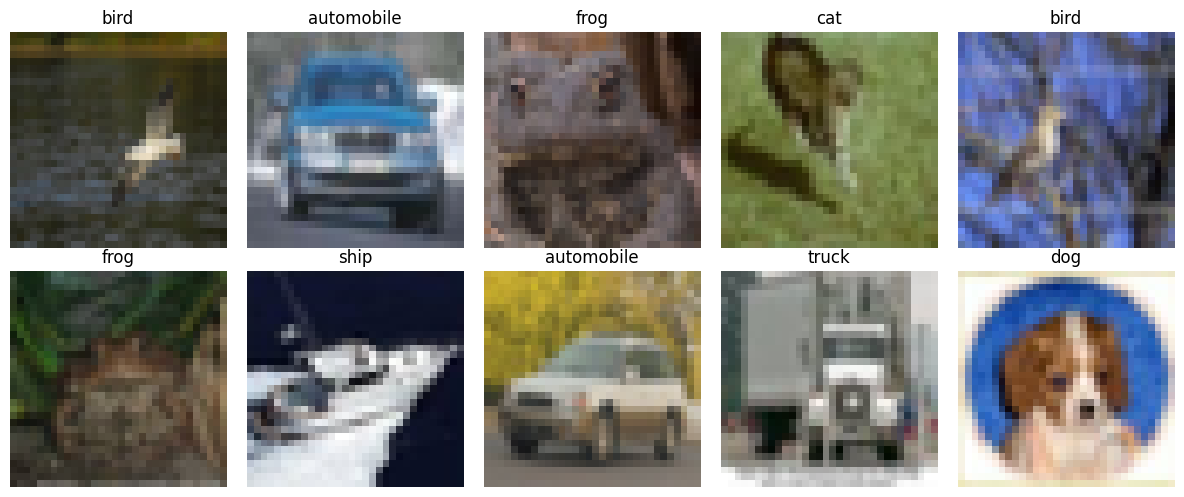

In [28]:
classes = train_dataset.classes

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(classes[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [29]:
class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)

        return x

In [30]:
model = CNN().to(device)

sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images.to(device)

output = model(sample_images)

print("Размер входных данных:", sample_images.shape)
print("Размер выходных данных:", output.shape)

Размер входных данных: torch.Size([128, 3, 32, 32])
Размер выходных данных: torch.Size([128, 10])


In [31]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 20

In [32]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    average_loss = running_loss / total
    accuracy = correct / total
    classification_error = 1 - accuracy

    return average_loss, accuracy, classification_error

In [33]:
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    average_loss = running_loss / total
    accuracy = correct / total
    classification_error = 1 - accuracy

    return average_loss, accuracy, classification_error

In [34]:
import time

train_losses = []
train_accuracies = []
train_errors = []

test_losses = []
test_accuracies = []
test_errors = []

for epoch in range(epochs):

    start_time = time.time()

    train_loss, _, _ = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    train_loss, train_accuracy, train_error = evaluate(
        model, train_loader, criterion, device
    )

    test_loss, test_accuracy, test_error = evaluate(
        model, test_loader, criterion, device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)
    train_errors.append(train_error)

    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)
    test_errors.append(test_error)

    elapsed_time = time.time() - start_time

    print(
        f"Эпоха [{epoch + 1}/{epochs}]  "
        f"Время: {elapsed_time:.1f} сек.  "
        f"Ошибка обучения: {train_error * 100:.2f}%  "
        f"Точность обучения: {train_accuracy * 100:.2f}%  "
        f"Ошибка теста: {test_error * 100:.2f}%  "
        f"Точность теста: {test_accuracy * 100:.2f}%"
    )

Эпоха [1/20]  Время: 45.4 сек.  Ошибка обучения: 50.07%  Точность обучения: 49.93%  Ошибка теста: 50.06%  Точность теста: 49.94%
Эпоха [2/20]  Время: 53.9 сек.  Ошибка обучения: 41.67%  Точность обучения: 58.33%  Ошибка теста: 42.23%  Точность теста: 57.77%
Эпоха [3/20]  Время: 44.1 сек.  Ошибка обучения: 34.90%  Точность обучения: 65.10%  Ошибка теста: 36.62%  Точность теста: 63.38%
Эпоха [4/20]  Время: 42.9 сек.  Ошибка обучения: 30.78%  Точность обучения: 69.22%  Ошибка теста: 33.35%  Точность теста: 66.65%
Эпоха [5/20]  Время: 44.4 сек.  Ошибка обучения: 28.01%  Точность обучения: 71.99%  Ошибка теста: 30.90%  Точность теста: 69.10%
Эпоха [6/20]  Время: 44.5 сек.  Ошибка обучения: 26.69%  Точность обучения: 73.31%  Ошибка теста: 30.26%  Точность теста: 69.74%
Эпоха [7/20]  Время: 43.6 сек.  Ошибка обучения: 23.17%  Точность обучения: 76.83%  Ошибка теста: 27.95%  Точность теста: 72.05%
Эпоха [8/20]  Время: 44.6 сек.  Ошибка обучения: 21.77%  Точность обучения: 78.23%  Ошибка теста:

In [35]:
final_test_loss, final_test_accuracy, final_test_error = evaluate(
    model, test_loader, criterion, device
)

print("Результат на тестовой выборке")
print(f"Точность классификации: {final_test_accuracy * 100:.2f}%")
print(f"Классификационная ошибка: {final_test_error * 100:.2f}%")
print(f"Функция потерь: {final_test_loss:.4f}")

Результат на тестовой выборке
Точность классификации: 76.26%
Классификационная ошибка: 23.74%
Функция потерь: 0.7990


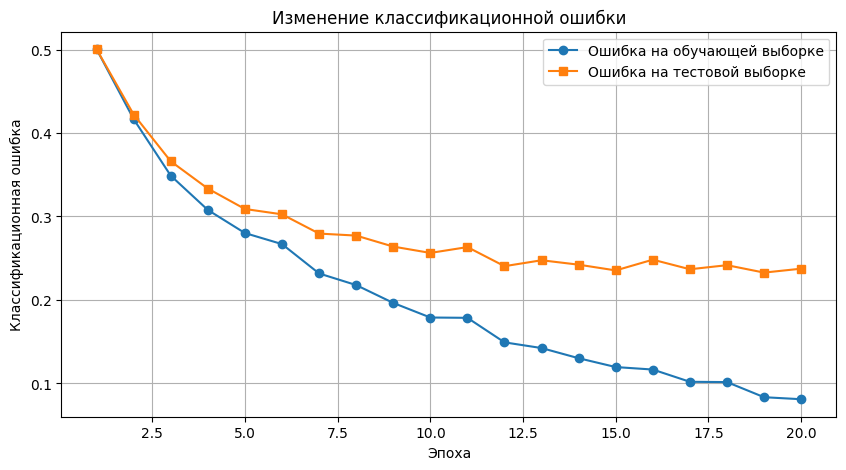

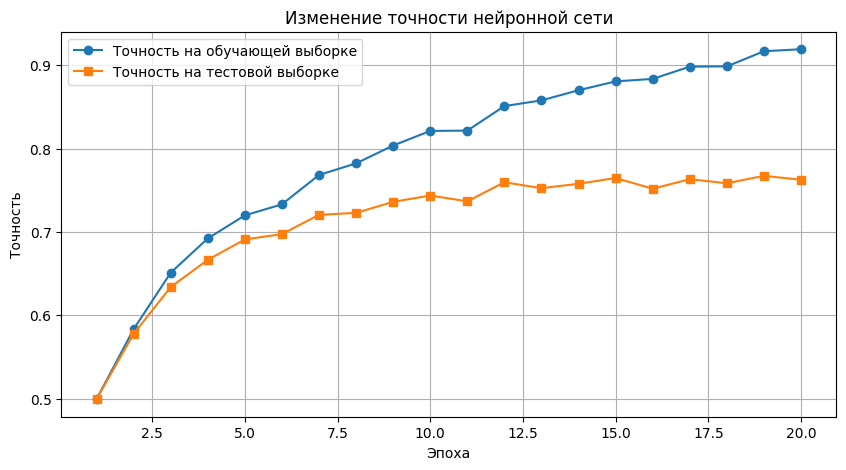

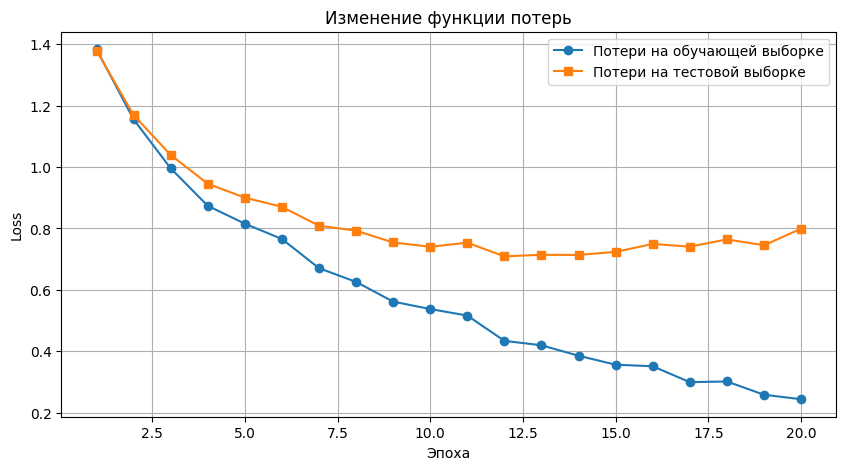

In [36]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, epochs + 1),
    train_errors,
    marker="o",
    label="Ошибка на обучающей выборке"
)

plt.plot(
    range(1, epochs + 1),
    test_errors,
    marker="s",
    label="Ошибка на тестовой выборке"
)

plt.xlabel("Эпоха")
plt.ylabel("Классификационная ошибка")
plt.title("Изменение классификационной ошибки")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    range(1, epochs + 1),
    train_accuracies,
    marker="o",
    label="Точность на обучающей выборке"
)

plt.plot(
    range(1, epochs + 1),
    test_accuracies,
    marker="s",
    label="Точность на тестовой выборке"
)

plt.xlabel("Эпоха")
plt.ylabel("Точность")
plt.title("Изменение точности нейронной сети")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker="o",
    label="Потери на обучающей выборке"
)

plt.plot(
    range(1, epochs + 1),
    test_losses,
    marker="s",
    label="Потери на тестовой выборке"
)

plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("Изменение функции потерь")
plt.legend()
plt.grid(True)
plt.show()

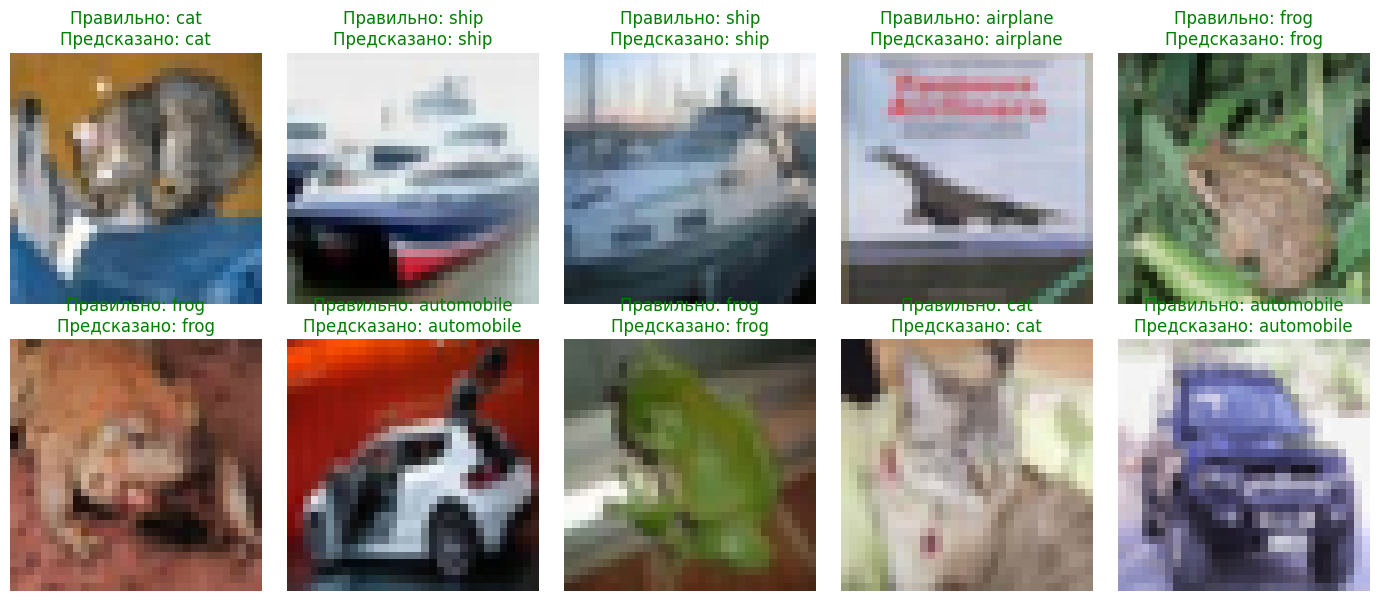

In [37]:
model.eval()

images, labels = next(iter(test_loader))

images_device = images.to(device)

with torch.no_grad():
    outputs = model(images_device)
    predictions = outputs.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0)

    true_label = classes[labels[i].item()]
    predicted_label = classes[predictions[i].item()]

    ax.imshow(image)
    ax.set_title(
        f"Правильно: {true_label}\nПредсказано: {predicted_label}",
        color="green" if true_label == predicted_label else "red"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()